# 03. Régua de cobrança

**Objetivo:** transformar os scores do modelo numa ação de cobrança para cada cliente da carteira, respondendo à pergunta do projeto: quanto do caixa previsto está em risco e qual abordagem cada cliente deve receber para recuperar esse valor sem desgastar o relacionamento.

**Entrada:** `analytics.client_scores` (probabilidade de atraso e valor esperado em risco, do notebook 02) e `analytics.client_base`.

**Avaliação honesta:** os scores de cada cliente vieram de um modelo que não o viu no treino (validação cruzada), então é possível medir a régua na carteira inteira com o que de fato aconteceu no período.

**Valor a receber:** o valor previsto para vencer no período, calculado pelas condições dos contratos no dia do corte. É o valor que a empresa conheceria naquele dia, então a fila não usa nenhuma informação do futuro.

## 1. Preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists())
sys.path.append(str(ROOT / "src"))

from sqlalchemy.types import NVARCHAR, Integer, SmallInteger

from db import read_query, write_table
from modeling import capture_at_top

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Dados

In [2]:
query = """
SELECT
    b.client_id,
    b.recent_pct_late,
    b.hist_pct_late,
    b.recent_max_days_late,
    b.scheduled_window_amount,
    b.window_amount_due,
    b.target_late_15,
    s.risk_probability,
    s.expected_value_at_risk,
    s.risk_decile
FROM analytics.client_base AS b
INNER JOIN analytics.client_scores AS s
    ON s.client_id = b.client_id
ORDER BY b.client_id  -- ordem fixa: muitos clientes têm a mesma probabilidade, e o desempate precisa ser sempre igual
"""
df = read_query(query)

# Valor a receber: o previsto no dia do corte, pelas condições dos contratos
df["value"] = df["scheduled_window_amount"]
# Valor em risco real: o valor previsto dos clientes que de fato atrasaram mais de 15 dias
df["actual_value_at_risk"] = df["value"] * df["target_late_15"]

print(f"{len(df):,} clientes")
print(f"Valor previsto para o período, no dia do corte: {df['value'].sum():,.0f}")
print(f"Valor esperado em risco (modelo): {df['expected_value_at_risk'].sum():,.0f}")
print(f"Valor em risco real (clientes que atrasaram): {df['actual_value_at_risk'].sum():,.0f}")

156,333 clientes
Valor previsto para o período, no dia do corte: 41,121,283,847
Valor esperado em risco (modelo): 696,915,644
Valor em risco real (clientes que atrasaram): 745,624,728


## 3. Qual fila recupera mais dinheiro, e quanto disso é mérito do modelo?

Quatro formas de montar a fila da cobrança, do mais simples ao mais completo:
- **só valor:** primeiro quem tem mais a pagar no período, sem olhar risco nenhum;
- **regra × valor:** a regra simples do notebook 02 (% de atraso recente) transformada em probabilidade e multiplicada pelo valor a receber;
- **modelo, só probabilidade:** primeiro quem tem mais chance de atrasar, qualquer que seja o valor;
- **modelo × valor** (valor esperado em risco): primeiro quem representa mais dinheiro em risco.

Comparar "regra × valor" com "modelo × valor" separa o ganho que vem de olhar o valor do ganho que vem do modelo. A probabilidade da regra é calculada por calibração isotônica em validação cruzada: cada cliente recebe a taxa de atraso observada em clientes parecidos com ele pela regra, sem usar o próprio resultado.

In [3]:
def out_of_fold_rule_probability(score, y, seed=42):
    """Transforma o score da regra numa probabilidade, sem que o cliente veja o próprio resultado."""
    prob = np.zeros(len(score))
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    for train_idx, test_idx in folds.split(score, y):
        iso = IsotonicRegression(out_of_bounds="clip").fit(score[train_idx], y[train_idx])
        prob[test_idx] = iso.predict(score[test_idx])
    return prob


rule = (df["recent_pct_late"].fillna(0) + df["hist_pct_late"] / 1000).to_numpy()
df["rule_probability"] = out_of_fold_rule_probability(rule, df["target_late_15"].to_numpy())

queues = {
    "só valor": df["value"],
    "regra × valor": df["rule_probability"] * df["value"],
    "modelo, só probabilidade": df["risk_probability"],
    "modelo × valor": df["expected_value_at_risk"],
}

rows = []
for share in (0.05, 0.10, 0.20, 0.30):
    for name, score in queues.items():
        cases, value = capture_at_top(df["target_late_15"], score, df["value"], share)
        rows.append({"% da carteira contatada": f"{share:.0%}", "fila": name,
                     "% dos clientes em risco": cases, "% do valor em risco": value})
queue_table = pd.DataFrame(rows).set_index(["% da carteira contatada", "fila"])
queue_table

% dos clientes em risco  \
% da carteira contatada fila                                                
5%                      só valor                                    0.063   
                        regra × valor                               0.185   
                        modelo, só probabilidade                    0.358   
                        modelo × valor                              0.269   
10%                     só valor                                    0.123   
                        regra × valor                               0.287   
                        modelo, só probabilidade                    0.464   
                        modelo × valor                              0.363   
20%                     só valor                                    0.224   
                        regra × valor                               0.425   
                        modelo, só probabilidade                    0.590   
                        modelo × valor                              0.489   
30%                     só valor                                    0.320   
                        regra × valor                               0.526   
                        modelo, só probabilidade                    0.676   
                        modelo × valor                              0.583   

                                                  % do valor em risco  
% da carteira contatada fila                                           
5%                      só valor                                0.255  
                        regra × valor                           0.390  
                        modelo, só probabilidade                0.324  
                        modelo × valor                          0.472  
10%                     só valor                                0.411  
                        regra × valor                           0.539  
                        modelo, só probabilidade                0.473  
                        modelo × valor                          0.589  
20%                     só valor                                0.599  
                        regra × valor                           0.713  
                        modelo, só probabilidade                0.622  
                        modelo × valor                          0.742  
30%                     só valor                                0.721  
                        regra × valor                           0.809  
                        modelo, só probabilidade                0.707  
                        modelo × valor                          0.826

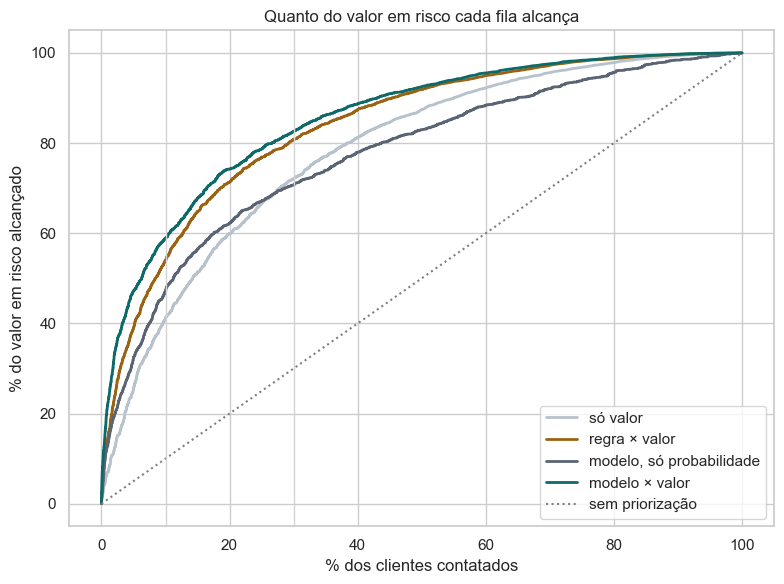

In [4]:
def value_curve(score):
    order = np.argsort(-np.asarray(score), kind="stable")
    captured = np.cumsum(df["actual_value_at_risk"].to_numpy()[order]) / df["actual_value_at_risk"].sum()
    return np.arange(1, len(df) + 1) / len(df) * 100, captured * 100


colors = {"só valor": "#b8c2cc", "regra × valor": "#9a6212",
          "modelo, só probabilidade": "#5a6473", "modelo × valor": "#0d6a68"}
fig, ax = plt.subplots(figsize=(8, 6))
for name, score in queues.items():
    x, y = value_curve(score)
    ax.plot(x, y, label=name, color=colors[name], linewidth=2)
ax.plot([0, 100], [0, 100], color="grey", linestyle=":", label="sem priorização")
for share in (10, 30):
    ax.axvline(share, color="lightgrey", linewidth=1)
ax.set_xlabel("% dos clientes contatados")
ax.set_ylabel("% do valor em risco alcançado")
ax.set_title("Quanto do valor em risco cada fila alcança")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_fila_por_valor.png", dpi=150)
plt.show()

## 4. A régua

A fila é ordenada pelo **valor esperado em risco**, porque a pergunta do projeto é sobre caixa. A carteira é dividida em quatro ações, da mais intensa para a mais leve:

| Ação | Quem recebe | O que é |
| --- | --- | --- |
| **Renegociação** | 10% do topo da fila **e** com atraso acima de 30 dias nos 6 meses antes do corte | Oferta de novo acordo de pagamento, para quem já mostra dificuldade |
| **Contato** | Restante dos 10% do topo da fila | Ligação ou mensagem pessoal da equipe antes do vencimento |
| **Lembrete** | Os 20% seguintes da fila | Mensagem automática antes do vencimento |
| **Monitoramento** | Os 70% restantes | Sem ação extra; acompanhamento normal |

Os cortes de 10% e 30% representam uma equipe que consegue atender pessoalmente 1 em cada 10 clientes e mandar mensagens automáticas para mais 2 em cada 10. Na prática, esses cortes seriam ajustados à capacidade real da equipe.

In [5]:
ACTIONS = ["Renegociação", "Contato", "Lembrete", "Monitoramento"]

df["priority_rank"] = df["expected_value_at_risk"].rank(ascending=False, method="first").astype(int)
queue_share = df["priority_rank"] / len(df)

df["collection_action"] = np.select(
    [
        (queue_share <= 0.10) & (df["recent_max_days_late"] > 30),
        queue_share <= 0.10,
        queue_share <= 0.30,
    ],
    ACTIONS[:3],
    default="Monitoramento",
)
df["action_order"] = df["collection_action"].map({a: i for i, a in enumerate(ACTIONS, start=1)})

total_actual = df["actual_value_at_risk"].sum()
total_cases = df["target_late_15"].sum()
strategy = (
    df.groupby("collection_action")
    .agg(
        clientes=("client_id", "size"),
        taxa_de_risco_real=("target_late_15", "mean"),
        clientes_em_risco=("target_late_15", "sum"),
        valor_a_receber=("value", "sum"),
        valor_esperado_em_risco=("expected_value_at_risk", "sum"),
        valor_em_risco_real=("actual_value_at_risk", "sum"),
    )
    .reindex(ACTIONS)
)
strategy.insert(1, "% da carteira", strategy["clientes"] / len(df) * 100)
strategy["% dos clientes em risco"] = strategy["clientes_em_risco"] / total_cases * 100
strategy["% do valor em risco real"] = strategy["valor_em_risco_real"] / total_actual * 100
strategy["taxa_de_risco_real"] = strategy["taxa_de_risco_real"] * 100
strategy

,clientes,% da carteira,taxa_de_risco_real,clientes_em_risco,valor_a_receber,valor_esperado_em_risco,valor_em_risco_real,% dos clientes em risco,% do valor em risco real
collection_action,,,,,,,,,
Renegociação,547,0.350,29.433,161.000,"145,680,912.230","37,245,913.560","43,917,074.720",6.143,5.890
Contato,15086,9.650,5.237,790.000,"10,797,256,736.110","354,158,484.260","395,438,272.790",30.141,53.034
Lembrete,31266,20.000,1.849,578.000,"15,235,222,003.060","171,703,688.150","176,409,182.260",22.053,23.659
Monitoramento,109434,70.001,0.998,"1,092.000","14,943,124,195.860","133,807,558.040","129,860,198.130",41.663,17.416


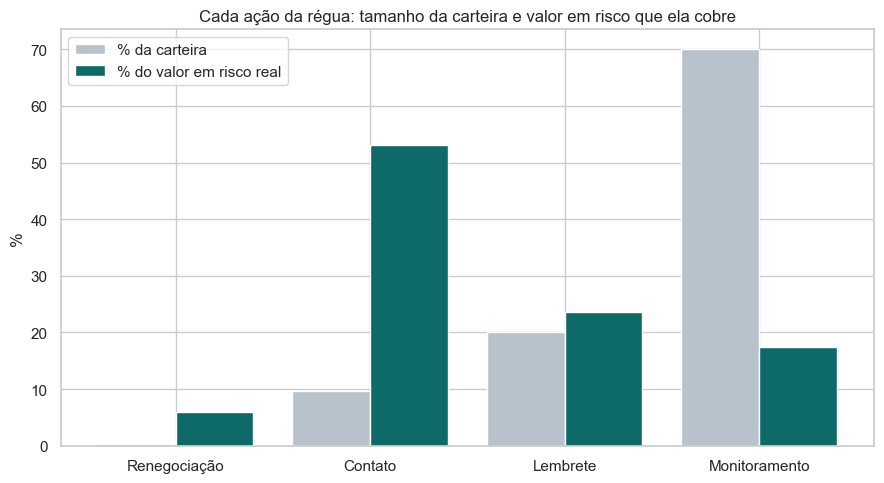

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(ACTIONS))
ax.bar(x - 0.2, strategy["% da carteira"], width=0.4, label="% da carteira", color="#b8c2cc")
ax.bar(x + 0.2, strategy["% do valor em risco real"], width=0.4, label="% do valor em risco real", color="#0d6a68")
ax.set_xticks(x, ACTIONS)
ax.set_ylabel("%")
ax.set_title("Cada ação da régua: tamanho da carteira e valor em risco que ela cobre")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_regua_de_cobranca.png", dpi=150)
plt.show()

## 5. Gravação no banco

A ação de cada cliente e a posição dele na fila são gravadas em `analytics.collection_strategy`, para o Power BI montar a lista priorizada da cobrança.

In [7]:
output = df[["client_id", "priority_rank", "collection_action", "action_order"]]
write_table(output, "collection_strategy", dtype={
    "client_id": Integer(),
    "priority_rank": Integer(),
    "collection_action": NVARCHAR(20),  # NVARCHAR guarda os acentos de "Renegociação" sem depender do banco
    "action_order": SmallInteger(),
})
print(f"{len(output):,} clientes gravados em analytics.collection_strategy")

156,333 clientes gravados em analytics.collection_strategy


## 6. Resumo para a próxima etapa

In [8]:
print("Comparação das filas:")
print(queue_table.to_string(), "\n")
print("Régua de cobrança:")
print(strategy[["clientes", "% da carteira", "taxa_de_risco_real", "% dos clientes em risco",
                "valor_esperado_em_risco", "% do valor em risco real"]].to_string())

Comparação das filas:
                                                  % dos clientes em risco  % do valor em risco
% da carteira contatada fila                                                                  
5%                      só valor                                    0.063                0.255
                        regra × valor                               0.185                0.390
                        modelo, só probabilidade                    0.358                0.324
                        modelo × valor                              0.269                0.472
10%                     só valor                                    0.123                0.411
                        regra × valor                               0.287                0.539
                        modelo, só probabilidade                    0.464                0.473
                        modelo × valor                              0.363                0.589
20%                     só v

## 7. Conclusões

**Quanto do ganho vem do valor e quanto vem do modelo.** Contatando 10% da carteira, cada fila alcança esta parte do valor em risco:
- só valor (sem olhar risco): 41,1%;
- regra × valor: 53,9%;
- modelo, só probabilidade: 47,3%;
- modelo × valor: 58,9%.

Olhar o valor a receber é o que mais pesa: mesmo sem modelo, a regra × valor já alcança 53,9%. O modelo acrescenta 5,0 pontos sobre ela, e o ganho é maior no topo da lista (47,2% contra 39,0% com 5% da carteira, 8,2 pontos). Com 30% da carteira, as duas filas ficam próximas (82,6% contra 80,9%). O modelo vale mais justamente onde a equipe começa a trabalhar.

**A troca entre clientes e valor é consciente:** a fila por valor esperado alcança menos clientes em risco que a fila só por probabilidade (36,3% contra 46,4% no top 10%), porque prioriza quem representa mais dinheiro. Para uma pergunta de caixa, é a escolha certa.

**A régua concentra o esforço onde está o dinheiro:**
- **Renegociação:** 547 clientes (0,35% da carteira) com taxa real de atraso de 29,4%, cerca de 17 vezes a média: clientes do topo da fila que já tiveram atraso acima de 30 dias recentemente;
- **Contato:** 15.086 clientes (9,6%) que respondem por 53,0% do valor em risco;
- **Renegociação e contato juntos:** 10% da carteira e 58,9% do valor em risco;
- **Lembrete:** 31.266 clientes (20%) e mais 23,7% do valor em risco;
- **Monitoramento:** 70% da carteira, com taxa de atraso de 1,0% e 17,4% do valor em risco.

**Em resumo:** com ação pessoal em 1 de cada 10 clientes e mensagens automáticas para mais 2 de cada 10, a cobrança cobre 82,6% do valor que de fato ficou em risco.

**Sem informação do futuro na fila:** o valor a receber é o previsto no dia do corte pelas condições dos contratos (ver `docs/decisoes.md`, item 22), então a fila poderia ter sido montada naquele dia.

**Ponto de atenção:** o valor esperado em risco estimado pelo modelo (696,9 milhões) ficou 6,5% abaixo do valor que de fato ficou em risco (745,6 milhões). Para planejamento de caixa, a estimativa deve ser tratada como um piso.

**Limitação:** os cortes de 10% e 30% representam uma capacidade de equipe hipotética. Na prática, seriam ajustados ao tamanho da equipe e ao custo de cada ação.
